In [1]:
from spectral_cube import SpectralCube
from reproject import reproject_interp
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS
from astropy import coordinates, wcs, units as u
from astropy.visualization import simple_norm
from astropy.visualization.wcsaxes import add_scalebar
from aces_figure_configuration import mymap, mymap2
import matplotlib.pyplot as plt
import regions
from regions import PixCoord, CirclePixelRegion, PolygonPixelRegion

fig_dir = '/blue/adamginsburg/abulatek/brick/first_results/figures'

In [2]:
def remove_abs_coords(axis):
    # Remove the absolute coordinates from a set of axes with built-in WCS
    ra = axis.coords["ra"]
    dec = axis.coords["dec"]
    ra.set_ticks_visible(False)
    ra.set_ticklabel_visible(False)
    dec.set_ticks_visible(False)
    dec.set_ticklabel_visible(False)
    ra.set_axislabel("")
    dec.set_axislabel("")

def overlay_rel_coords(axis):
    # Create an overlay with relative coordinates centered on the Brick maser
    remove_abs_coords(axis)
    crd = coordinates.SkyCoord("17:46:10.6339473267 -28:42:17.9807702398", frame='icrs', unit=(u.h, u.deg))
    aframe = crd.skyoffset_frame()
    overlay = axis.get_coords_overlay(aframe)
    ra_offset = overlay["lon"]
    dec_offset = overlay["lat"]
    ra_offset.set_axislabel("RA offset [arcsec]")
    dec_offset.set_axislabel("Dec offset [arcsec]")
    ra_offset.set_major_formatter("s.s")
    dec_offset.set_major_formatter("s.s")
    ra_offset.set_ticks_position("bt")
    ra_offset.set_ticklabel_position("b")
    dec_offset.set_ticks_position("lr")
    dec_offset.set_ticklabel_position("l")
    ra_offset.set_axislabel_position("b")
    dec_offset.set_axislabel_position("l")

In [3]:
# ACES 12-m continuum + MUSTANG-2
acesfmustangfn = '/orange/adamginsburg/ACES/mosaics/continuum/12m_continuum_commonbeam_circular_reimaged_mosaic_MUSTANGfeathered.fits'
hdul = fits.open(acesfmustangfn)
acesmustangim = hdul[0].data
wcs_aces = WCS(hdul[0].header)

In [4]:
# Spitzer
i1 = fits.open('/orange/adamginsburg/spitzer/GLIMPSE/GLM_00000+0000_mosaic_I1.fits')
i2 = fits.open('/orange/adamginsburg/spitzer/GLIMPSE/GLM_00000+0000_mosaic_I2.fits')
i3 = fits.open('/orange/adamginsburg/spitzer/GLIMPSE/GLM_00000+0000_mosaic_I3.fits')
i4 = fits.open('/orange/adamginsburg/spitzer/GLIMPSE/GLM_00000+0000_mosaic_I4.fits')
m24 = fits.open('/orange/adamginsburg/spitzer/mips/MG0000n005_024.fits')
# Make your own header in a weird way (adapted from larger_context.ipynb)
ww_orig = wcs.WCS()
ww_orig.wcs.ctype = 'RA---TAN', 'DEC--TAN'
ww_orig.wcs.crval = 266.5356389808593, -28.712998625026 # Central coord
ww_orig.wcs.cdelt = -3.333333300000E-04, 3.333333300000E-04 # Pixel scale in degrees
ww_orig.wcs.crpix = 125, 175 # Pixel coord corresponding to CRVAL (change this to change shape)
ww_orig.wcs.cunit = 'deg', 'deg'
# Then extract the header and add dimension information for the cutout
tgt_header = ww_orig.to_header()
tgt_header['NAXIS'] = 2
tgt_header['NAXIS1'] = 250
tgt_header['NAXIS2'] = 400
# Then make a new WCS from that header
ww = wcs.WCS(tgt_header)
ww.calc_footprint()
# Make a polygon region for the cutout
poly = regions.PolygonSkyRegion(coordinates.SkyCoord(ww.calc_footprint()[:,0], ww.calc_footprint()[:,1], unit=(u.deg, u.deg), frame=ww.wcs.radesys.lower()))
wwspitz = wcs.WCS(i1[0].header)
polymask = poly.to_pixel(wwspitz).to_mask()
# Use reproject to cut out The Brick from each imported GLIMPSE image
tgt_header_spitzer = tgt_header.copy()
i1r,_ = reproject_interp(i1, tgt_header_spitzer)
i2r,_ = reproject_interp(i2, tgt_header_spitzer)
i3r,_ = reproject_interp(i3, tgt_header_spitzer)
i4r,_ = reproject_interp(i4, tgt_header_spitzer)
mipsr,_ = reproject_interp(m24, tgt_header_spitzer)
# RGB map 124
rgb_spitzer_124 = np.array([
    (i4r), # R
    (i2r), # G
    (i1r), # B
]).swapaxes(0,2).swapaxes(0,1)
# RGB map 234
rgb_spitzer_234 = np.array([
    (i4r), # R
    (i3r), # G
    (i2r), # B
]).swapaxes(0,2).swapaxes(0,1)
# RGB map 134
rgb_spitzer = np.array([
    (i4r), # R
    (i3r), # G
    (i1r), # B
]).swapaxes(0,2).swapaxes(0,1)
# RGB map 24MIPS
rgb_spitzer_mips = np.array([
    (mipsr), # R
    (i4r),   # G
    (i2r),   # B
]).swapaxes(0,2).swapaxes(0,1)

# Stretches from Savannah: https://github.com/SpacialTree/lactea-filament/blob/main/lactea-filament/cutout_manager.py
rgb_spitzer_scaled = np.array([simple_norm(rgb_spitzer[:,:,0], stretch='asinh', vmin=-1, vmax=350)(rgb_spitzer[:,:,0]),
                               simple_norm(rgb_spitzer[:,:,1], stretch='asinh', vmin=-1, vmax=200)(rgb_spitzer[:,:,1]),
                               simple_norm(rgb_spitzer[:,:,2], stretch='asinh', vmin=-1, vmax=100)(rgb_spitzer[:,:,2]),]).swapaxes(0,2)#.swapaxes(0,1)

In [5]:
# Brick line survey
results = '/blue/adamginsburg/abulatek/brick/first_results/continuum_images'
# Get list of all continuum images
import glob
imagefns = glob.glob(f"{results}/brickmaser_cont_*_mtmfs_incl_adjparam*.image.tt0")
imagefns.remove('/blue/adamginsburg/abulatek/brick/first_results/continuum_images/brickmaser_cont_data_31_mtmfs_incl_adjparam.image.tt0')
imagefns.remove('/blue/adamginsburg/abulatek/brick/first_results/continuum_images/brickmaser_cont_data_41_mtmfs_incl_adjparam.image.tt0')
# Import the continuum images
contimages = []
for imagefn in imagefns:
    image = SpectralCube.read(imagefn, format='casa_image')
    image_K = image.to(u.K)
    contimages.append(image_K)
# Reorder continuum images from lowest to highest frequency
lowestfreqs = [np.min(contimage.spectral_axis).value for contimage in contimages]
correct_order = np.argsort(lowestfreqs)
contimages_ordered = [contimages[i] for i in correct_order] # How do the frequencies get assigned to the images?
# Choose the ~93 GHz continuum image
contimage = contimages_ordered[0]

/blue/adamginsburg/abulatek/conda/envs/py312/lib/python3.12/site-packages/casa_formats_io/casa_dask.py:248: RuntimeWarning: divide by zero encountered in scalar remainder
  factors = [f for f in range(stacks[dim] + 1) if stacks[dim] % f == 0]
/blue/adamginsburg/abulatek/conda/envs/py312/lib/python3.12/site-packages/casa_formats_io/casa_dask.py:248: RuntimeWarning: divide by zero encountered in scalar remainder
  factors = [f for f in range(stacks[dim] + 1) if stacks[dim] % f == 0]
/blue/adamginsburg/abulatek/conda/envs/py312/lib/python3.12/site-packages/casa_formats_io/casa_dask.py:248: RuntimeWarning: divide by zero encountered in scalar remainder
  factors = [f for f in range(stacks[dim] + 1) if stacks[dim] % f == 0]
/blue/adamginsburg/abulatek/conda/envs/py312/lib/python3.12/site-packages/casa_formats_io/casa_dask.py:248: RuntimeWarning: divide by zero encountered in scalar remainder
  factors = [f for f in range(stacks[dim] + 1) if stacks[dim] % f == 0]
/blue/adamginsburg/abulatek/

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.1754140885136465..2.130917383377168].


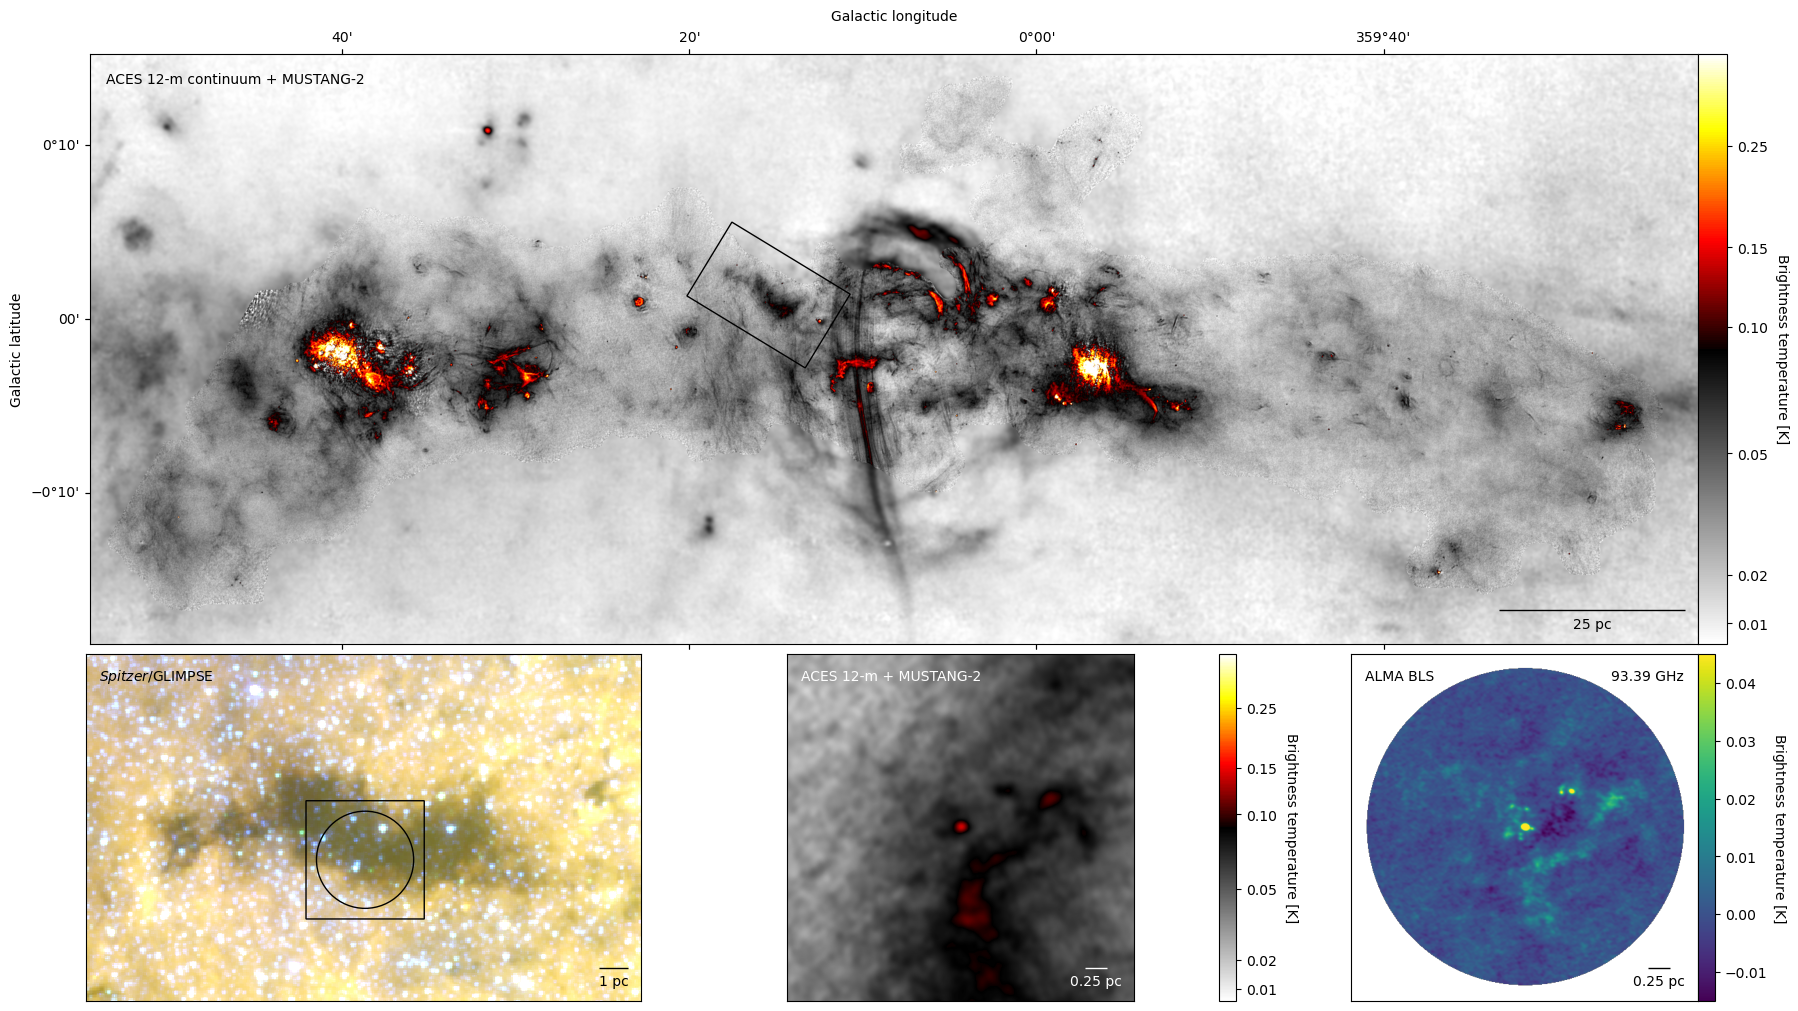

In [10]:
## Set up the figure
fig = plt.figure(figsize=(18,10), layout="constrained")
gs = fig.add_gridspec(2, 3, width_ratios=[1.5,1,1], height_ratios=[1.7,1])

## ACES+MUSTANG subplot
ax_aces = fig.add_subplot(gs[0,:], projection=wcs_aces)
im_aces = ax_aces.imshow(acesmustangim, norm=simple_norm(acesmustangim, stretch='asinh', min_percent=0.5, max_percent=99.95), cmap=mymap)
cbar_aces = plt.colorbar(im_aces, ax=ax_aces, pad=0)
cbar_aces.set_ticks([0.01, 0.02, 0.05, 0.1, 0.15, 0.25])
cbar_aces.set_label(f"Brightness temperature [{hdul[0].header['BUNIT']}]", rotation=270, labelpad=15)
ax_aces.set_xlabel("Galactic longitude")
ax_aces.set_ylabel("Galactic latitude")
# Add a scale bar
gc_distance = 8.0*u.kpc
scalebar_length = 25*u.pc
scalebar_angle = (scalebar_length / gc_distance).to(u.deg, equivalencies=u.dimensionless_angles())
add_scalebar(ax_aces, scalebar_angle, label='25 pc', color='k', frame=False)
# Add a square for the Spitzer cutout
poly.to_pixel(wcs_aces).plot(ax=ax_aces, color='k', linewidth=1)
# Move longitude label to the top
glon = ax_aces.coords["glon"]
glon.set_ticklabel_position("t")
# Add label to plot
plt.text(0.01, 0.95, 'ACES 12-m continuum + MUSTANG-2', transform=ax_aces.transAxes, size=10)

## Brick line survey continuum image
ax_bls = fig.add_subplot(gs[1,2], projection=contimage[0].wcs)
im_bls = ax_bls.imshow(contimage[0].value, origin='lower', cmap='viridis', norm='linear', vmax=0.045, vmin=-0.015)
cbar_bls = plt.colorbar(im_bls, ax=ax_bls, pad=0)
cbar_bls.set_label(f"Brightness temperature [{contimage[0].unit.to_string(format = 'latex_inline')}]", rotation=270, labelpad=15)
# Add a scale bar
gc_distance = 8.0*u.kpc
scalebar_length = 0.25*u.pc
scalebar_angle = (scalebar_length / gc_distance).to(u.deg, equivalencies=u.dimensionless_angles())
add_scalebar(ax_bls, scalebar_angle, label='0.25 pc', color='k', frame=False)
# Add center frequency to plot
freq = str(round(contimage.spectral_extrema[0].to(u.GHz).value, 2))+' GHz'
plt.text(0.75, 0.925, freq, transform=ax_bls.transAxes, size=10)
# Add label to plot
plt.text(0.04, 0.925, 'ALMA BLS', transform=ax_bls.transAxes, size=10)
# Remove the absolute coordinates
remove_abs_coords(ax_bls)

## ACES+MUSTANG zoom-in subplot
wcs_small = contimage.wcs.dropaxis(2)
aces_arr, footprint = reproject_interp(hdul[0], wcs_small,
                                       shape_out=np.shape(contimage[0].value))
ax_aceszoom = fig.add_subplot(gs[1,1], projection=wcs_small)
im_aceszoom = ax_aceszoom.imshow(aces_arr, norm=simple_norm(acesmustangim, stretch='asinh', 
                                                            min_percent=0.5, max_percent=99.95), cmap=mymap)
cbar_aceszoom = plt.colorbar(im_aceszoom, ax=ax_aceszoom, pad=0)
cbar_aceszoom.set_ticks([0.01, 0.02, 0.05, 0.1, 0.15, 0.25])
cbar_aceszoom.set_label(f"Brightness temperature [{hdul[0].header['BUNIT']}]", rotation=270, labelpad=15)
# Add a scale bar
gc_distance = 8.0*u.kpc
scalebar_length = 0.25*u.pc
scalebar_angle = (scalebar_length / gc_distance).to(u.deg, equivalencies=u.dimensionless_angles())
add_scalebar(ax_aceszoom, scalebar_angle, label='0.25 pc', color='w', frame=False)
# Add label to plot
plt.text(0.04, 0.925, 'ACES 12-m + MUSTANG-2', transform=ax_aceszoom.transAxes, size=10, color='w')
# Remove the absolute coordinates
remove_abs_coords(ax_aceszoom)

## Spitzer subplot
ax_spitzer = fig.add_subplot(gs[1,0], projection=ww_orig, slices=('y', 'x')) # Slices switches ra/dec
im_spitzer = ax_spitzer.imshow(rgb_spitzer_scaled, interpolation='none')
ax_spitzer.invert_xaxis() # Necessary to have dec increasing to the right
# Put a circle where our pointing is
circ = regions.CircleSkyRegion(coordinates.SkyCoord('17:46:10.63 -28:42:17.8', unit=(u.h, u.deg), frame='icrs'), 42*u.arcsec)
pixcirc = circ.to_pixel(ww_orig)
# print(pixcirc)
pixcirc = CirclePixelRegion(PixCoord(x=198.16171642355232, y=101.23206478173392), radius=35.00000137178028) # Switch x/y from above, also get pixel radius from above
pixcirc.plot(ax=ax_spitzer, edgecolor='k', linewidth=1)
# Add a square for the ACES+MUSTANG cutout
bls_footprint = contimage.wcs.dropaxis(2).calc_footprint(header=contimage.header) # Can't extract frame
small_sq = regions.PolygonSkyRegion(coordinates.SkyCoord(bls_footprint[:,0], bls_footprint[:,1], unit=(u.deg, u.deg), frame='icrs'))
pixsq = small_sq.to_pixel(ww_orig)
# print(pixsq)
pixsq = PolygonPixelRegion(PixCoord(x=[155.5336221, 240.70029985, 240.70646856, 155.53979641], y=[58.59041142, 58.58423536, 143.75091319, 143.75708332],)) # Switch x/y from above
pixsq.plot(ax=ax_spitzer, color='k', linewidth=1)
# Add a scale bar
gc_distance = 8.0*u.kpc
scalebar_length = 1.0*u.pc
scalebar_angle = (scalebar_length / gc_distance).to(u.deg, equivalencies=u.dimensionless_angles())
add_scalebar(ax_spitzer, scalebar_angle, label='1 pc', color='k', frame=False)
# Add label to plot
plt.text(0.025, 0.925, '$Spitzer$/GLIMPSE', transform=ax_spitzer.transAxes, size=10)
# Remove absolute coordinates
remove_abs_coords(ax_spitzer)

# NOTE: WHEN SAVING, DON'T USE tight_layout
plt.savefig(fig_dir+'/'+f'new_larger_context.png') # , bbox_inches='tight')
plt.savefig(fig_dir+'/'+f'new_larger_context.pdf') # , bbox_inches='tight')

plt.show()